In [51]:
## Block A｜一次性设置（路径/市场/工具函数）
import os, glob, re
import pandas as pd
from datetime import timedelta

CHARTS_DIR = "spotify_charts"   

MARKETS = {
    "Global": "global",
    "US": "us",
    "ID": "id",
}

def norm_text(s: str) -> str:
    """lower + 去掉所有非字母数字，用于稳健匹配曲名符号差异"""
    return re.sub(r"[^a-z0-9]+", "", str(s).lower())

def build_7day_filenames(market_code: str, release_date: pd.Timestamp):
    """从 release_date 起，生成 7 天窗口要用的文件名列表（只生成名字，不读文件）"""
    out = []
    for i in range(7):
        d = (release_date + timedelta(days=i)).strftime("%Y-%m-%d")
        out.append(f"regional-{market_code}-daily-{d}.csv")
    return out

In [52]:
## Block B｜读配置表 + 生成“需要下载的文件清单”

anchor_df = pd.read_csv("group_release_anchor_config.csv")

# ✅ 你现在应该是 8 首歌
print("anchors:", anchor_df.shape)
display(anchor_df)

# ✅ 日期列统一转 datetime（你如果是 2017-06-22 这种格式，这行没问题）
anchor_df["release_date"] = pd.to_datetime(anchor_df["release_date"])

needed = []
for _, r in anchor_df.iterrows():
    rd = r["release_date"]
    for market_code in MARKETS.values():
        needed.extend(build_7day_filenames(market_code, rd))

needed = sorted(set(needed))
print("needed_files:", len(needed))
print("first 10:", needed[:10])
print("last 10:", needed[-10:])

anchors: (8, 5)


,track_id,track_name,release_date,anchor_type,anchor_reason
0,BP03,As If It’s Your Last,2017/6/22,Main,Standalone single anchoring pre-album era
1,BP04,DDU-DU DDU-DU,2018/6/15,Main,Square Up global breakout anchor
2,BP05,Kill This Love,2019/4/5,Main,EP anchor tied to Coachella-era exposure
3,BP06,How You Like That,2020/6/26,Pre,Album pre-release signal driving initial momentum
4,BP07,Lovesick Girls,2020/10/2,Main,The Album official title-track anchor
5,BP08,Pink Venom,2022/8/19,Pre,Born Pink pre-release signal for global attent...
6,BP09,Shut Down,2022/9/16,Main,Born Pink album anchor with synchronized globa...
7,BP10,Jump,2025/7/11,Main,Digital single with live premiere to release t...


needed_files: 168
first 10: ['regional-global-daily-2017-06-22.csv', 'regional-global-daily-2017-06-23.csv', 'regional-global-daily-2017-06-24.csv', 'regional-global-daily-2017-06-25.csv', 'regional-global-daily-2017-06-26.csv', 'regional-global-daily-2017-06-27.csv', 'regional-global-daily-2017-06-28.csv', 'regional-global-daily-2018-06-15.csv', 'regional-global-daily-2018-06-16.csv', 'regional-global-daily-2018-06-17.csv']
last 10: ['regional-us-daily-2022-09-20.csv', 'regional-us-daily-2022-09-21.csv', 'regional-us-daily-2022-09-22.csv', 'regional-us-daily-2025-07-11.csv', 'regional-us-daily-2025-07-12.csv', 'regional-us-daily-2025-07-13.csv', 'regional-us-daily-2025-07-14.csv', 'regional-us-daily-2025-07-15.csv', 'regional-us-daily-2025-07-16.csv', 'regional-us-daily-2025-07-17.csv']


In [ ]:
## Block C｜下载/校验数据（只做数据，不做分析）

In [53]:
have = set(os.listdir(CHARTS_DIR))
missing = [f for f in needed if f not in have]

print("have:", len(have))
print("missing:", len(missing))
print("missing sample:", missing[:20])

have: 169
missing: 0
missing sample: []


In [54]:
def is_html_file(path, nbytes=2000):
    try:
        with open(path, "rb") as f:
            head = f.read(nbytes).lower()
        return b"<!doctype html" in head or b"<html" in head
    except Exception:
        return False

def audit_charts_folder(charts_dir=CHARTS_DIR):
    files = sorted([f for f in os.listdir(charts_dir) if f.endswith(".csv")])
    html_files = []
    for f in files:
        p = os.path.join(charts_dir, f)
        if is_html_file(p):
            html_files.append(f)
    return files, html_files

files_all, html_bad = audit_charts_folder()
print("csv files in folder:", len(files_all))
print("html bad files:", len(html_bad))
print("sample bad:", html_bad[:10])

csv files in folder: 168
html bad files: 0
sample bad: []


In [55]:
have = set(os.listdir(CHARTS_DIR))
missing_after = [f for f in needed if f not in have]
print("missing_after:", len(missing_after))
print("sample:", missing_after[:20])

_, html_bad = audit_charts_folder()
print("html_bad_after:", len(html_bad))

missing_after: 0
sample: []
html_bad_after: 0


In [56]:
## Block D1｜读取 7 天窗口 + 抽取某首歌（稳健版）
def get_7day_files(market_code: str, release_date: pd.Timestamp):
    files = []
    for i in range(7):
        d = (release_date + timedelta(days=i)).strftime("%Y-%m-%d")
        path = os.path.join(CHARTS_DIR, f"regional-{market_code}-daily-{d}.csv")
        if os.path.exists(path):
            files.append(path)
    return sorted(files)

def load_7day_market_df(market_name: str, market_code: str, release_date: pd.Timestamp):
    files = get_7day_files(market_code, release_date)
    if not files:
        return pd.DataFrame()

    chunks = []
    for f in files:
        df = pd.read_csv(f)
        # 从文件名提取日期
        filename = os.path.basename(f)
        date_str = "-".join(filename.replace(".csv", "").split("-")[-3:])
        df["chart_date"] = pd.to_datetime(date_str, format="%Y-%m-%d")
        df["market"] = market_name
        chunks.append(df)

    out = pd.concat(chunks, ignore_index=True)
    return out

def extract_track_series(market_df: pd.DataFrame, track_name: str, release_date: pd.Timestamp):
    if market_df.empty:
        return pd.DataFrame()

    target = norm_text(track_name)

    df = market_df.copy()
    df["track_norm"] = df["track_name"].map(norm_text)

    hit = df[
        (df["track_norm"] == target) &
        (df["artist_names"].str.contains("BLACKPINK", case=False, na=False))
    ].copy()

    if hit.empty:
        return pd.DataFrame()

    hit["day_since_release"] = (hit["chart_date"] - release_date).dt.days
    hit = hit.sort_values("day_since_release")
    return hit

In [57]:
## Block D2｜指标函数（7天窗口）
def compute_metrics_7d(ts: pd.DataFrame):
    if ts.empty:
        return {
            "days_observed": 0,
            "peak_day": None,
            "peak_streams": None,
            "half_life_day_7d": None,
            "rank_retention_3d": None,
            "sum_streams_7d": None
        }

    ts = ts.sort_values("day_since_release").copy()
    days_observed = int(ts["day_since_release"].nunique())

    # peak
    peak_idx = ts["streams"].idxmax()
    peak_day = int(ts.loc[peak_idx, "day_since_release"])
    peak_streams = int(ts.loc[peak_idx, "streams"])
    half_threshold = peak_streams * 0.5

    # half-life within 7d after peak
    after_peak = ts[ts["day_since_release"] >= peak_day]
    half_rows = after_peak[after_peak["streams"] <= half_threshold]
    half_life_day = int(half_rows.iloc[0]["day_since_release"]) if len(half_rows) > 0 else None

    # rank retention (Day0->Day2)
    r0 = ts.loc[ts["day_since_release"] == 0, "rank"]
    r2 = ts.loc[ts["day_since_release"] == 2, "rank"]
    rank_retention_3d = None if (len(r0)==0 or len(r2)==0) else int(r2.iloc[0] - r0.iloc[0])

    # 7d 累计流量（窗口内可用天数求和）
    sum_streams_7d = int(ts["streams"].sum())

    return {
        "days_observed": days_observed,
        "peak_day": peak_day,
        "peak_streams": peak_streams,
        "half_life_day_7d": half_life_day,
        "rank_retention_3d": rank_retention_3d,
        "sum_streams_7d": sum_streams_7d
    }

In [58]:
## Block D3｜批量跑：8 anchors × 3 市场 → 两张表（long_df + summary_df）
anchor_df = pd.read_csv("group_release_anchor_config.csv")
anchor_df["release_date"] = pd.to_datetime(anchor_df["release_date"])

all_long = []
all_summary = []

for _, row in anchor_df.iterrows():
    track_id = row["track_id"]
    track_name = row["track_name"]
    release_date = row["release_date"]
    anchor_type = row["anchor_type"]

    for market_name, market_code in MARKETS.items():
        market_df = load_7day_market_df(market_name, market_code, release_date)
        ts = extract_track_series(market_df, track_name, release_date)

        if not ts.empty:
            ts_out = ts[["market","chart_date","day_since_release","rank","streams","track_name","artist_names"]].copy()
            ts_out["track_id"] = track_id
            ts_out["anchor_type"] = anchor_type
            all_long.append(ts_out)

        m = compute_metrics_7d(ts)
        all_summary.append({
            "track_id": track_id,
            "track_name": track_name,
            "release_date": release_date,
            "anchor_type": anchor_type,
            "market": market_name,
            **m
        })

long_df = pd.concat(all_long, ignore_index=True)
summary_df = pd.DataFrame(all_summary)

print("long_df:", long_df.shape)
print("summary_df:", summary_df.shape)
display(summary_df.sort_values(["track_id","market"]))

long_df: (152, 9)
summary_df: (24, 11)


,track_id,track_name,release_date,anchor_type,market,days_observed,peak_day,peak_streams,half_life_day_7d,rank_retention_3d,sum_streams_7d
0,BP03,As If It’s Your Last,2017-06-22,Main,Global,0,NaN,NaN,None,NaN,NaN
2,BP03,As If It’s Your Last,2017-06-22,Main,ID,7,1.0,39320.0,None,-39.0,205620.0
1,BP03,As If It’s Your Last,2017-06-22,Main,US,0,NaN,NaN,None,NaN,NaN
3,BP04,DDU-DU DDU-DU,2018-06-15,Main,Global,7,1.0,1317999.0,None,-27.0,8462430.0
5,BP04,DDU-DU DDU-DU,2018-06-15,Main,ID,7,1.0,123800.0,None,0.0,765343.0
4,BP04,DDU-DU DDU-DU,2018-06-15,Main,US,5,1.0,253811.0,None,-30.0,1174528.0
6,BP05,Kill This Love,2019-04-05,Main,Global,7,0.0,4003909.0,None,2.0,22870205.0
8,BP05,Kill This Love,2019-04-05,Main,ID,7,0.0,477163.0,None,0.0,2538952.0
7,BP05,Kill This Love,2019-04-05,Main,US,7,0.0,767637.0,None,-1.0,4369678.0
9,BP06,How You Like That,2020-06-26,Pre,Global,7,1.0,4894830.0,None,-3.0,28978705.0


In [59]:
##Block D4｜立刻做“质量检查”（有没有匹配不到的歌）
check = summary_df.copy()
check["matched"] = check["days_observed"] > 0

pivot = check.pivot_table(
    index=["track_id","track_name"],
    columns="market",
    values="matched",
    aggfunc="first"
)

display(pivot)

,market,Global,ID,US
track_id,track_name,,,
BP03,As If It’s Your Last,False,True,False
BP04,DDU-DU DDU-DU,True,True,True
BP05,Kill This Love,True,True,True
BP06,How You Like That,True,True,True
BP07,Lovesick Girls,True,True,True
BP08,Pink Venom,True,True,True
BP09,Shut Down,True,True,True
BP10,Jump,True,True,True


In [60]:
## Block E1｜先补一个“衰减指标”（解决你 half_life 全是 None）
# 1) 从 long_df 里算：每首歌/每市场的 peak_streams、day6_streams、retention_ratio
tmp = long_df.copy()

group_keys = ["track_id", "track_name", "anchor_type", "market"]

# peak streams per track/market
peak = tmp.groupby(group_keys, as_index=False)["streams"].max()
peak = peak.rename(columns={"streams": "peak_streams_calc"})

# day6 streams per track/market（Day6 可能缺失）
day6 = tmp[tmp["day_since_release"] == 6].copy()
day6 = day6.groupby(group_keys, as_index=False)["streams"].sum()
day6 = day6.rename(columns={"streams": "day6_streams"})

metrics2 = peak.merge(day6, on=group_keys, how="left")
metrics2["day6_streams"] = metrics2["day6_streams"].fillna(0).astype(int)
metrics2["retention_day6_vs_peak"] = metrics2["day6_streams"] / metrics2["peak_streams_calc"]

display(metrics2.sort_values(["track_id", "market"]))

## retention_day6_vs_peak 越高 = 7天“抗跌/续航”越强；越低 = “爆发但回落快”。

,track_id,track_name,anchor_type,market,peak_streams_calc,day6_streams,retention_day6_vs_peak
0,BP03,As If It's Your Last,Main,ID,39320,27636,0.702848
1,BP04,DDU-DU DDU-DU,Main,Global,1317999,1089931,0.826959
2,BP04,DDU-DU DDU-DU,Main,ID,123800,112771,0.910913
3,BP04,DDU-DU DDU-DU,Main,US,253811,0,0.000000
4,BP05,Kill This Love,Main,Global,4003909,3045081,0.760527
5,BP05,Kill This Love,Main,ID,477163,289806,0.607352
6,BP05,Kill This Love,Main,US,767637,592871,0.772332
7,BP06,How You Like That,Pre,Global,4894830,3637860,0.743205
8,BP06,How You Like That,Pre,ID,568250,426032,0.749726
9,BP06,How You Like That,Pre,US,802535,563235,0.701820


In [61]:
release_map = summary_df[["track_id", "release_date"]].drop_duplicates()
metrics2 = metrics2.merge(release_map, on="track_id", how="left")

display(metrics2.sort_values(["track_id","market"]))

,track_id,track_name,anchor_type,market,peak_streams_calc,day6_streams,retention_day6_vs_peak,release_date
0,BP03,As If It's Your Last,Main,ID,39320,27636,0.702848,2017-06-22
1,BP04,DDU-DU DDU-DU,Main,Global,1317999,1089931,0.826959,2018-06-15
2,BP04,DDU-DU DDU-DU,Main,ID,123800,112771,0.910913,2018-06-15
3,BP04,DDU-DU DDU-DU,Main,US,253811,0,0.000000,2018-06-15
4,BP05,Kill This Love,Main,Global,4003909,3045081,0.760527,2019-04-05
5,BP05,Kill This Love,Main,ID,477163,289806,0.607352,2019-04-05
6,BP05,Kill This Love,Main,US,767637,592871,0.772332,2019-04-05
7,BP06,How You Like That,Pre,Global,4894830,3637860,0.743205,2020-06-26
8,BP06,How You Like That,Pre,ID,568250,426032,0.749726,2020-06-26
9,BP06,How You Like That,Pre,US,802535,563235,0.701820,2020-06-26


In [62]:
# Block E2｜按 market + anchor_type 汇总 retention

agg_retention = (
    metrics2
    .groupby(["market", "anchor_type"], as_index=False)
    .agg(
        n_tracks=("track_id", "nunique"),
        avg_retention=("retention_day6_vs_peak", "mean"),
        median_retention=("retention_day6_vs_peak", "median"),
    )
)

display(agg_retention.sort_values(["market", "anchor_type"]))

,market,anchor_type,n_tracks,avg_retention,median_retention
0,Global,Main,5,0.763197,0.760527
1,Global,Pre,2,0.683890,0.683890
2,ID,Main,6,0.769221,0.754402
3,ID,Pre,2,0.787489,0.787489
4,US,Main,5,0.567292,0.611820
5,US,Pre,2,0.643767,0.643767


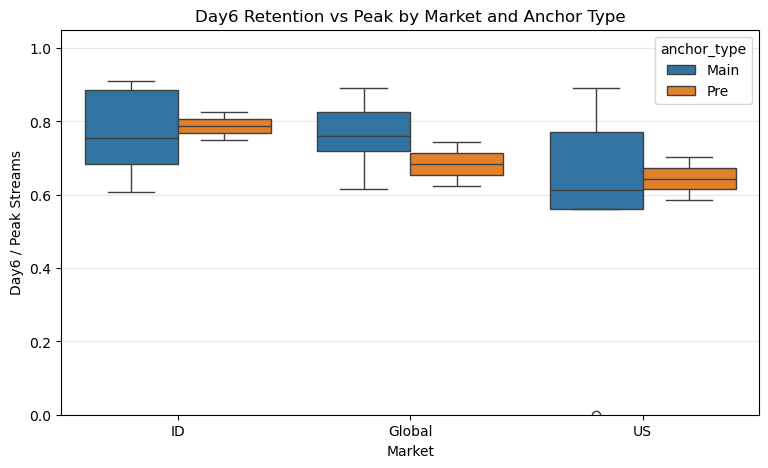

In [63]:
## Block E3 
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9,5))
sns.boxplot(
    data=metrics2,
    x="market",
    y="retention_day6_vs_peak",
    hue="anchor_type"
)
plt.ylim(0, 1.05)
plt.title("Day6 Retention vs Peak by Market and Anchor Type")
plt.ylabel("Day6 / Peak Streams")
plt.xlabel("Market")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [64]:
# Block F1｜Jump vs Historical Main Anchors (Same Market)

jump = metrics2[metrics2["track_id"] == "BP10"].copy()
main_hist = metrics2[
    (metrics2["anchor_type"] == "Main") &
    (metrics2["track_id"] != "BP10")
].copy()

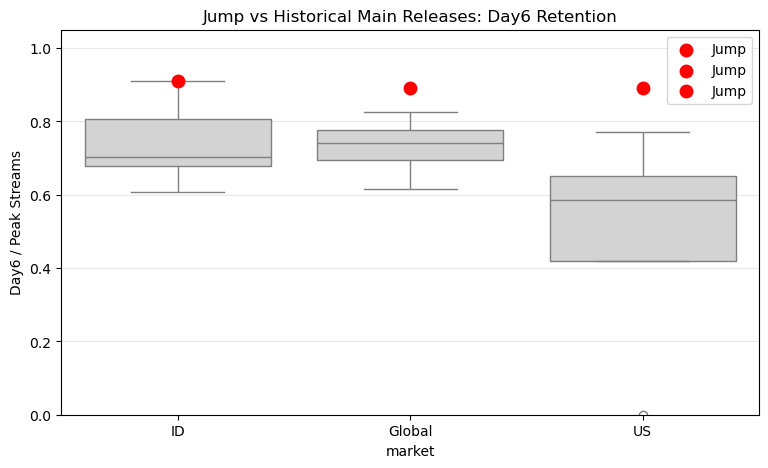

In [65]:
## F2｜按 market 对比 retention 分布

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

sns.boxplot(
    data=main_hist,
    x="market",
    y="retention_day6_vs_peak",
    color="lightgray"
)

sns.stripplot(
    data=jump,
    x="market",
    y="retention_day6_vs_peak",
    color="red",
    size=10,
    label="Jump"
)

plt.ylim(0, 1.05)
plt.title("Jump vs Historical Main Releases: Day6 Retention")
plt.ylabel("Day6 / Peak Streams")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [66]:
## F2.1｜只保留历史 Main releases（不含 Jump）
hist_main = metrics2[
    (metrics2["anchor_type"] == "Main") &
    (metrics2["track_name"] != "JUMP")
].copy()

In [67]:
## F2.2｜单独拿出 Jump
jump = metrics2[metrics2["track_name"] == "JUMP"].copy()

In [68]:
## F2.3｜计算 percentile + z-score
import numpy as np
from scipy.stats import percentileofscore

rows = []

for mkt in ["Global", "US", "ID"]:
    hist_vals = hist_main.loc[
        hist_main["market"] == mkt, "retention_day6_vs_peak"
    ].dropna()

    jump_val = jump.loc[
        jump["market"] == mkt, "retention_day6_vs_peak"
    ].values[0]

    percentile = percentileofscore(hist_vals, jump_val) / 100
    z = (jump_val - hist_vals.mean()) / hist_vals.std()

    q1 = hist_vals.quantile(0.25)
    q3 = hist_vals.quantile(0.75)
    iqr = q3 - q1
    outlier = jump_val > q3 + 1.5 * iqr

    rows.append({
        "market": mkt,
        "jump_retention": jump_val,
        "percentile": percentile,
        "z_score": z,
        "outlier_IQR": outlier
    })

jump_stats = pd.DataFrame(rows)
display(jump_stats)

,market,jump_retention,percentile,z_score,outlier_IQR
0,Global,0.892127,1.0,1.823952,False
1,US,0.891671,1.0,1.205178,False
2,ID,0.910546,0.8,1.428043,False


In [69]:
## Block G0｜先给 8 个 anchor 打上 era 标签（结构阶段）

import pandas as pd

anchors = pd.read_csv(
    "group_release_anchor_config.csv",
    parse_dates=["release_date"]
)

display(anchors)
anchors.info()

,track_id,track_name,release_date,anchor_type,anchor_reason
0,BP03,As If It’s Your Last,2017-06-22,Main,Standalone single anchoring pre-album era
1,BP04,DDU-DU DDU-DU,2018-06-15,Main,Square Up global breakout anchor
2,BP05,Kill This Love,2019-04-05,Main,EP anchor tied to Coachella-era exposure
3,BP06,How You Like That,2020-06-26,Pre,Album pre-release signal driving initial momentum
4,BP07,Lovesick Girls,2020-10-02,Main,The Album official title-track anchor
5,BP08,Pink Venom,2022-08-19,Pre,Born Pink pre-release signal for global attent...
6,BP09,Shut Down,2022-09-16,Main,Born Pink album anchor with synchronized globa...
7,BP10,Jump,2025-07-11,Main,Digital single with live premiere to release t...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   track_id       8 non-null      object        
 1   track_name     8 non-null      object        
 2   release_date   8 non-null      datetime64[ns]
 3   anchor_type    8 non-null      object        
 4   anchor_reason  8 non-null      object        
dtypes: datetime64[ns](1), object(4)
memory usage: 452.0+ bytes


In [70]:
anchors2 = anchors.copy()
anchors2["release_date"] = pd.to_datetime(anchors2["release_date"])

def assign_era(d):
    if d < pd.Timestamp("2020-01-01"):
        return "Early Globalization (2017–2019)"
    elif d < pd.Timestamp("2022-01-01"):
        return "Streaming Expansion (2020–2021)"
    elif d < pd.Timestamp("2023-01-01"):
        return "Born Pink Upgrade (2022)"
    else:
        return "Post-Tour Maintenance (2025)"

anchors2["era"] = anchors2["release_date"].apply(assign_era)

display(
    anchors2[["track_id","track_name","release_date","anchor_type","era"]]
)

,track_id,track_name,release_date,anchor_type,era
0,BP03,As If It’s Your Last,2017-06-22,Main,Early Globalization (2017–2019)
1,BP04,DDU-DU DDU-DU,2018-06-15,Main,Early Globalization (2017–2019)
2,BP05,Kill This Love,2019-04-05,Main,Early Globalization (2017–2019)
3,BP06,How You Like That,2020-06-26,Pre,Streaming Expansion (2020–2021)
4,BP07,Lovesick Girls,2020-10-02,Main,Streaming Expansion (2020–2021)
5,BP08,Pink Venom,2022-08-19,Pre,Born Pink Upgrade (2022)
6,BP09,Shut Down,2022-09-16,Main,Born Pink Upgrade (2022)
7,BP10,Jump,2025-07-11,Main,Post-Tour Maintenance (2025)


In [71]:
## Step G1｜把 Era 合并进 retention 指标表
## Block G1｜Merge Era into Retention Metrics (Clean Version)

# 目的：
# - 以 anchors2 里的 era 为唯一权威
# - 清除 metrics2 中历史残留/错误的 era
# - 得到一个可用于结构分析的统一表

metrics_with_era = (
    metrics2
    .drop(columns=["era"], errors="ignore")   # 删除 metrics2 里可能残留的 era
    .merge(
        anchors2[["track_id", "era"]],
        on="track_id",
        how="left",
        validate="m:1"   # 每个 track_id 只能对应一个 era（结构约束）
    )
)

# 核查结构
print(metrics_with_era.columns.tolist())

# 快速查看关键字段
display(
    metrics_with_era[
        ["track_id","track_name","market","anchor_type","era","retention_day6_vs_peak"]
    ].sort_values(["era","track_id","market"])
)

# 安全检查：是否有未分配 era 的行
print("era missing:", metrics_with_era["era"].isna().sum())

['track_id', 'track_name', 'anchor_type', 'market', 'peak_streams_calc', 'day6_streams', 'retention_day6_vs_peak', 'release_date', 'era']


,track_id,track_name,market,anchor_type,era,retention_day6_vs_peak
13,BP08,Pink Venom,Global,Pre,Born Pink Upgrade (2022),0.624575
14,BP08,Pink Venom,ID,Pre,Born Pink Upgrade (2022),0.825252
15,BP08,Pink Venom,US,Pre,Born Pink Upgrade (2022),0.585715
16,BP09,Shut Down,Global,Main,Born Pink Upgrade (2022),0.720393
17,BP09,Shut Down,ID,Main,Born Pink Upgrade (2022),0.805956
18,BP09,Shut Down,US,Main,Born Pink Upgrade (2022),0.611820
0,BP03,As If It's Your Last,ID,Main,Early Globalization (2017–2019),0.702848
1,BP04,DDU-DU DDU-DU,Global,Main,Early Globalization (2017–2019),0.826959
2,BP04,DDU-DU DDU-DU,ID,Main,Early Globalization (2017–2019),0.910913
3,BP04,DDU-DU DDU-DU,US,Main,Early Globalization (2017–2019),0.000000


era missing: 0


In [72]:
## Block G2｜Era-level Summary Table (Era × Market × Anchor Type)

g2 = (
    metrics_with_era
    .groupby(["era", "market", "anchor_type"], as_index=False)
    .agg(
        n_tracks=("track_id", "nunique"),
        avg_err6=("retention_day6_vs_peak", "mean"),
        median_err6=("retention_day6_vs_peak", "median"),
        min_err6=("retention_day6_vs_peak", "min"),
        max_err6=("retention_day6_vs_peak", "max"),
    )
    .sort_values(["era", "market", "anchor_type"])
)

display(g2)

,era,market,anchor_type,n_tracks,avg_err6,median_err6,min_err6,max_err6
0,Born Pink Upgrade (2022),Global,Main,1,0.720393,0.720393,0.720393,0.720393
1,Born Pink Upgrade (2022),Global,Pre,1,0.624575,0.624575,0.624575,0.624575
2,Born Pink Upgrade (2022),ID,Main,1,0.805956,0.805956,0.805956,0.805956
3,Born Pink Upgrade (2022),ID,Pre,1,0.825252,0.825252,0.825252,0.825252
4,Born Pink Upgrade (2022),US,Main,1,0.611820,0.611820,0.611820,0.611820
5,Born Pink Upgrade (2022),US,Pre,1,0.585715,0.585715,0.585715,0.585715
6,Early Globalization (2017–2019),Global,Main,2,0.793743,0.793743,0.760527,0.826959
7,Early Globalization (2017–2019),ID,Main,3,0.740371,0.702848,0.607352,0.910913
8,Early Globalization (2017–2019),US,Main,2,0.386166,0.386166,0.000000,0.772332
9,Post-Tour Maintenance (2025),Global,Main,1,0.892127,0.892127,0.892127,0.892127


In [73]:
## Block G2.1｜Pivot view (Main only)

g2_main = g2[g2["anchor_type"] == "Main"].copy()

pivot_main = g2_main.pivot_table(
    index="era",
    columns="market",
    values="avg_err6"
)

display(pivot_main)

market,Global,ID,US
era,,,
Born Pink Upgrade (2022),0.720393,0.805956,0.611820
Early Globalization (2017–2019),0.793743,0.740371,0.386166
Post-Tour Maintenance (2025),0.892127,0.910546,0.891671
Streaming Expansion (2020–2021),0.615981,0.677710,0.560635


In [74]:
## Block G2.2｜Main vs Pre gap within each era/market

pivot_type = g2.pivot_table(
    index=["era","market"],
    columns="anchor_type",
    values="avg_err6"
).reset_index()

pivot_type["main_minus_pre"] = pivot_type.get("Main", 0) - pivot_type.get("Pre", 0)

display(pivot_type.sort_values(["era","market"]))

anchor_type,era,market,Main,Pre,main_minus_pre
0,Born Pink Upgrade (2022),Global,0.720393,0.624575,0.095817
1,Born Pink Upgrade (2022),ID,0.805956,0.825252,-0.019296
2,Born Pink Upgrade (2022),US,0.611820,0.585715,0.026105
3,Early Globalization (2017–2019),Global,0.793743,NaN,NaN
4,Early Globalization (2017–2019),ID,0.740371,NaN,NaN
5,Early Globalization (2017–2019),US,0.386166,NaN,NaN
6,Post-Tour Maintenance (2025),Global,0.892127,NaN,NaN
7,Post-Tour Maintenance (2025),ID,0.910546,NaN,NaN
8,Post-Tour Maintenance (2025),US,0.891671,NaN,NaN
9,Streaming Expansion (2020–2021),Global,0.615981,0.743205,-0.127223


In [ ]:
## Dashboard创建

In [75]:
import os
print(os.getcwd())

/Users/apple/Desktop/BLACKPINK_global_spread_project/data


In [76]:
import os

OUT_DIR = os.path.abspath("../dashboard/data")
os.makedirs(OUT_DIR, exist_ok=True)
print("Export folder:", OUT_DIR)

Export folder: /Users/apple/Desktop/BLACKPINK_global_spread_project/dashboard/data


In [77]:
# Step 4 — Export dashboard data (final, clean)

metrics_with_era.to_csv(
    os.path.join(OUT_DIR, "metrics_with_era.csv"),
    index=False
)

g2.to_csv(
    os.path.join(OUT_DIR, "era_market_anchor_summary.csv"),
    index=False
)

pivot_type.to_csv(
    os.path.join(OUT_DIR, "main_vs_pre_gap.csv"),
    index=False
)

print("✅ Dashboard data exported:")
print(os.listdir(OUT_DIR))

✅ Dashboard data exported:
['metrics_with_era.csv', 'era_market_anchor_summary.csv', 'main_vs_pre_gap.csv']
